# Module 11.2 — Word2Vec vs GloVe 🧠

Bro, the main difference is how the two algorithms learn word embeddings. Both use the distributional hypothesis: words that occur in similar contexts tend to have related meanings.

- Word2Vec: learns by predicting words from their contexts, or contexts from words.
- GloVe: learns by fitting global word–context co-occurrence statistics.

Let's compare them from an NLP engineer's perspective.

## 1. Training objective


Word2Vec

Learns embeddings by optimizing a prediction task.

- CBOW: context → target word
- Skip-gram: target word → context words



GloVe

Learns embeddings by fitting co-occurrence counts.

- Builds a word–context matrix
- Fits vector relationships to its statistics

Word2Vec's Skip-gram with negative sampling learns to distinguish observed word–context pairs from sampled negative pairs. GloVe instead minimizes a weighted least-squares objective involving the logarithm of co-occurrence counts.

The distinction is the learning objective, not whether context matters: both algorithms use contextual information.

## 2. Local vs global information

This is the most important conceptual distinction, but there's a subtlety.

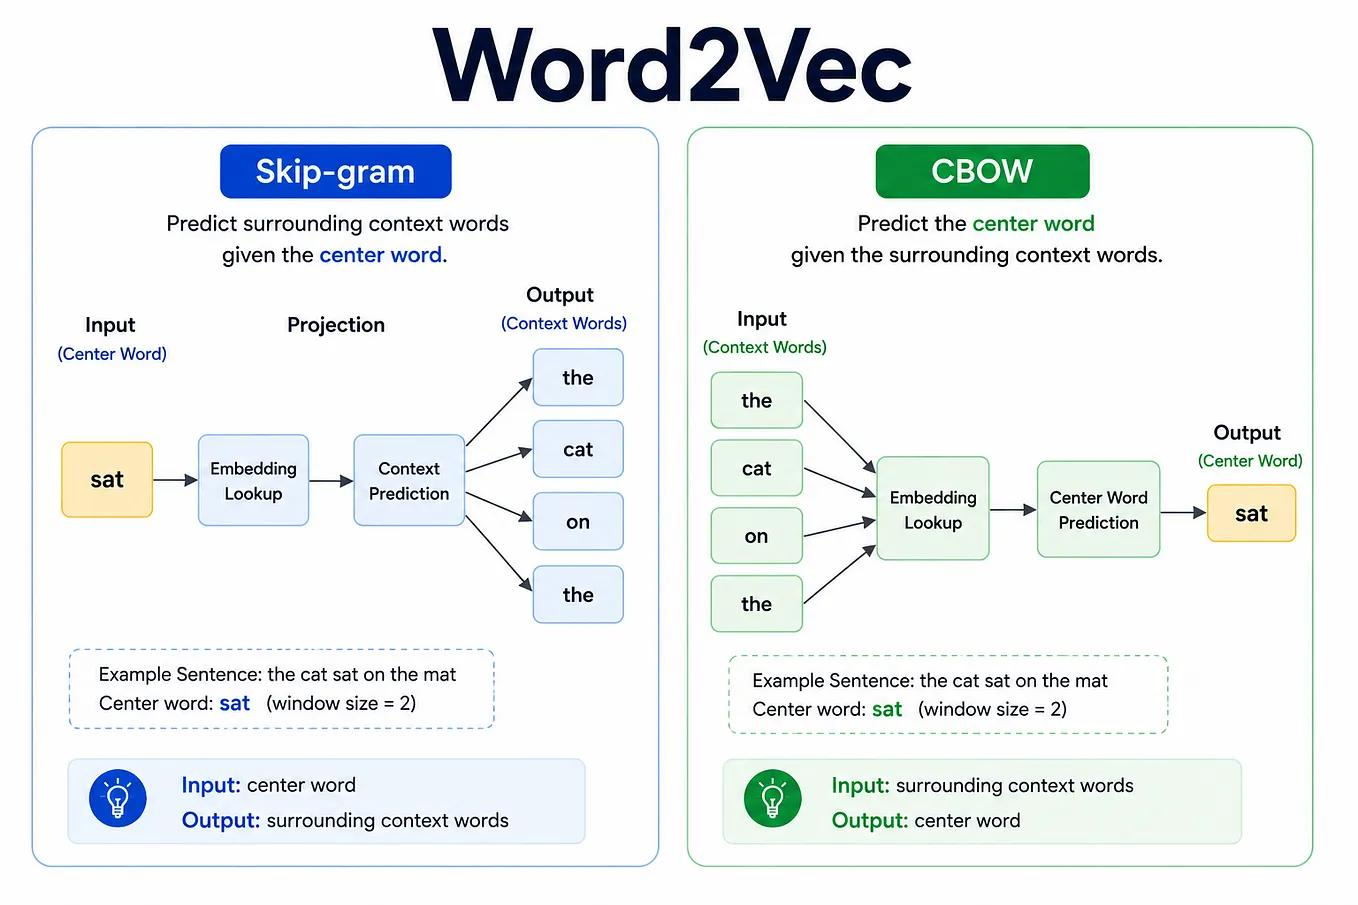

Word2Vec — local context windows

It generates training examples from nearby words. For example, given “the cat drinks milk,” the target `cat` can be paired with its surrounding words. Learning across many such examples captures useful patterns.

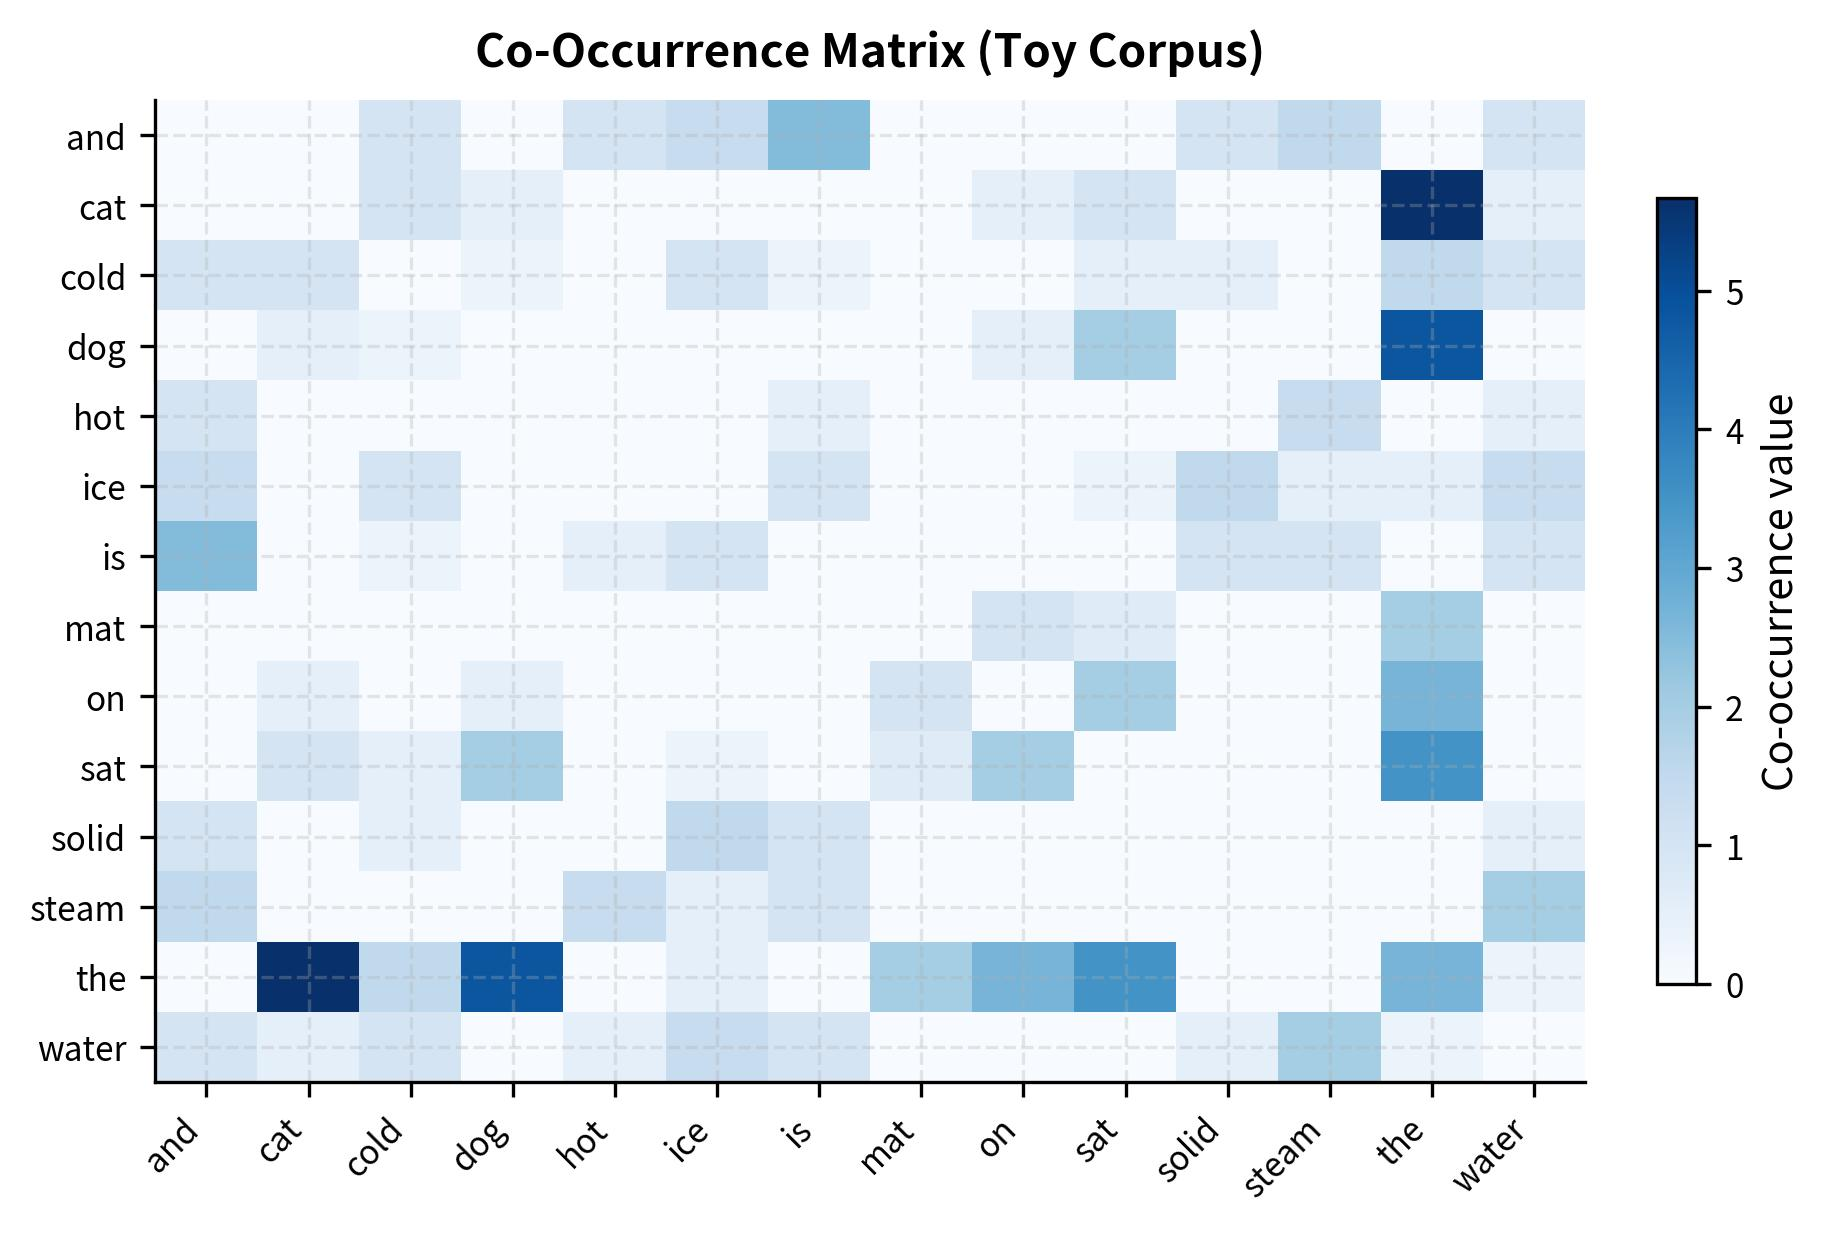

GloVe — global co-occurrence statistics

It aggregates context-window relationships into a corpus-wide count matrix, then learns embeddings from the nonzero counts. This explicitly incorporates global co-occurrence statistics into its objective.

Important nuance: Word2Vec also learns from the entire training corpus over many local windows. GloVe's advantage is not that Word2Vec ignores the corpus; it is that GloVe directly models aggregated co-occurrence counts.

## 3. Practical behaviour

| Aspect              | Word2Vec                                   | GloVe                                          |
| ------------------- | ------------------------------------------ | ---------------------------------------------- |
| Semantic similarity | Captures related words                     | Captures related words                         |
| Word analogies      | Can capture vector relationships           | Can capture vector relationships               |
| Training data       | Local-window training examples             | Aggregated co-occurrence counts                |
| Rare words          | Depends on training frequency and settings | Depends on co-occurrence evidence and settings |
| Unseen words        | No learned vector by default               | No learned vector by default                   |
| Contextual meaning  | Static embeddings                          | Static embeddings                              |

Both can produce useful word representations for text classification, clustering, and similarity tasks. Neither inherently creates a different vector for a word based on the sentence in which it appears.

For example, the word `bank` has financial and geographical meanings. A standard Word2Vec or GloVe embedding generally represents both meanings with the same word vector. Contextual models such as BERT address this limitation.

## 4. Which should you use?

- Word2Vec: A strong choice when you want to learn embeddings using a straightforward predictive objective.
- GloVe: A strong choice when you want to exploit aggregated co-occurrence statistics and use available pretrained vectors.
- Neither is universally better: Results depend on the corpus, vocabulary, embedding dimension, training configuration, and downstream task. The original GloVe paper reported competitive results on word-similarity and analogy benchmarks, but that does not establish universal superiority.
- 
## What you should remember 🎯

1. Word2Vec learns through a predictive objective; GloVe fits global co-occurrence statistics.
2. Both rely on the distributional hypothesis.
3. Word2Vec uses local context windows, while GloVe explicitly aggregates their co-occurrences.
4. Both produce static embeddings, so they do not resolve word meaning dynamically from sentence context.
5. Benchmark performance—not the algorithm's name alone—should guide your choice.

---